# 02. 学習した方策で実機を動かす (Colab ⇔ MQTT ⇔ ATOM ⇔ toio)

01 で学習した方策を Colab 上で 10Hz で実行し、MQTT 経由で ATOM Mate for toio のロボットを動かします。

```
Colab (方策) ──MQTT──> ブローカー ──Wi-Fi──> AtomS3 ──BLE──> toio
      <──── ToF / 位置 / 遅延 (20Hz) ─────────────┘
```

**事前準備** (詳しくは README.md):
1. AtomS3 に `firmware/atom_toio_bridge` を書き込み済み (`config.h` の Wi-Fi・MQTT・`TOPIC_PREFIX` を設定)
2. toio の電源を入れ、マットの上に置く。toio の LED が **青** なら接続完了 (DISARM 状態)
3. 01 ノートブックの学習結果 (`runs/ppo_avoid`) がドライブにある

> 実機がなくても `USE_VIRTUAL_ROBOT = True` にすると、仮想ロボット (シミュレータ) を相手に最後まで試せます。

**安全のために**: ロボットは AtomS3 の画面部分 (ボタン) を押して ARM するまで動きません。指令が 0.5 秒途切れると止まり、
ToF が 30mm 未満になると前進できなくなります。マットの外に落ちないよう、机の端では使わないでください。

## 1. セットアップ

In [1]:
# --- プロジェクトの場所 ---
# このフォルダ (robot-test) を Google ドライブの「マイドライブ」直下にアップロードしておく
from google.colab import drive
drive.mount('/content/drive')
PROJECT_DIR = '/content/drive/MyDrive/robot-test'  # ← アップロード先に合わせて変更

# GitHub に置いた場合はドライブの代わりに clone してもよい (学習結果の保存先はドライブを推奨)
# !git clone https://github.com/<user>/<repo>.git /content/robot-test
# PROJECT_DIR = '/content/robot-test'

import os, sys
os.chdir(PROJECT_DIR)
sys.path.insert(0, PROJECT_DIR)
%pip install -q -r requirements.txt

Mounted at /content/drive


## 2. MQTT の設定

`firmware/atom_toio_bridge/config.h` と **同じ値** にします。
パスワードは Colab の「シークレット」(左側の鍵アイコン) に保存して `userdata.get()` で読むのがおすすめです。

In [ ]:
MQTT = dict(
    host="broker.emqx.io",
    port=1883,
    topic_prefix="toio-sim2real/CHANGE-ME",  # ← config.h の TOPIC_PREFIX と同じに
    username=None,
    password=None,
    tls=False,
    transport="tcp",  # 1883 番ポートに出られない場合は "websockets" + port=8083 (EMQX の場合)
)
# from google.colab import userdata
# MQTT["username"], MQTT["password"] = userdata.get("MQTT_USER"), userdata.get("MQTT_PASSWORD")

USE_VIRTUAL_ROBOT = False  # True: 実機の代わりに仮想ロボットを Colab 内で動かす

RUN_DIR = f"{PROJECT_DIR}/runs/ppo_avoid"

In [3]:
from toio_sim2real.policies import load_trained, RuleBasedPolicy
from toio_sim2real.real_robot import MqttBridge, run_on_robot, default_goals_dot
from toio_sim2real import calibration as cal, viz

model, cfg = load_trained(RUN_DIR)

vrobot = None
if USE_VIRTUAL_ROBOT:
    from toio_sim2real.virtual_robot import VirtualRobot
    vrobot = VirtualRobot(cfg, n_obstacles=3, seed=0, **MQTT).start()

bridge = MqttBridge(**MQTT).connect()
st = bridge.wait_for_state()
print(f"ロボット: status={bridge.robot_status}  toio接続={st.toio_connected}  電池={st.battery}%  "
      f"{'ARM' if st.armed else 'DISARM'}")
print(f"位置: ({st.x_dot}, {st.y_dot}) {st.angle_deg}°  読み取り={'OK' if st.pos_valid else 'NG (マットに置いてください)'}  "
      f"ToF={st.tof_mm} mm")

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


ロボット: status=online  toio接続=True  電池=90%  DISARM
位置: (124, 136) 62°  読み取り=OK  ToF=269 mm


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 3. キャリブレーション (sim2real の確認)

実機の特性を測り、学習時のドメインランダマイゼーション (DR) の範囲に入っているか確認します。

### 3-1. 通信遅延
「ATOM がセンサーを読んでから、それを元にした指令が ATOM に届くまで」の時間を ATOM の時計で測ります (モーターは動きません)。

In [4]:
link = cal.link_check(bridge, seconds=5)
link

{'state_hz': 9.99671919591273,
 'latency_ms_median': 738.0,
 'latency_ms_p90': 972.0,
 'latency_ms_max': 1048.0,
 'battery': 90,
 'armed': False,
 'toio_connected': True}

### 3-2. ToF センサー
1. **toio の前方 40cm 以内に何も置かずに** 実行 → 床やマットを誤検出していないか
2. **toio の前方 10cm に箱などを置いて** 実行 → 100mm 前後が出れば、センサーが前を向いている

(仮想ロボットの場合は障害物の配置がランダムなので、ここの結果は参考程度で構いません)

In [11]:
tof_empty = cal.tof_check(bridge, seconds=3)
tof_empty

{'samples': 30,
 'valid_ratio': 1.0,
 'min_mm': 683.0,
 'median_mm': 698.5,
 'max_mm': 713.0}

In [13]:
tof_front = cal.tof_check(bridge, seconds=3)
print(tof_front)
print("OK: センサーは前を向いています" if 60 < tof_front["median_mm"] < 140
      else "⚠ 100mm 前後になりません。ATOM Mate の向き (ToF が toio の前方を向いているか) を確認してください")

{'samples': 22, 'valid_ratio': 1.0, 'min_mm': 113.0, 'median_mm': 118.0, 'max_mm': 120.0}
OK: センサーは前を向いています


### 3-3. 直進・旋回
**AtomS3 の画面部分を押して ARM** してから実行します (toio の LED が黄色になります)。
マットの中央付近、前方 15cm に何もない場所に置いてください。直進で約 13cm 進み、その場で 1 回転弱 (240° 前後) 回ります。

In [28]:
straight = cal.straight_test(bridge, cfg, unit=30, seconds=2)
turn = cal.turn_test(bridge, cfg, unit=20, seconds=2)
print(straight)
print(turn)

{'distance_mm': 160.8949579752267, 'speed_mm_s': 77.47700497049917, 'motor_gain': 0.9176445259170447, 'wheel_asymmetry': 0.9679129836597475, 'heading_error_deg': 1.396707893629504}
{'turn_rate_deg_s': 240.98025469373974, 'turn_gain': 0.9938100426129424}


In [ ]:
results = dict(link=link, straight=straight, turn=turn, tof_empty=tof_empty)
checks = cal.compare_with_dr(cfg, **results)
for ok, msg in checks:
    print("✅" if ok else "⚠️", msg)

if not all(ok for ok, _ in checks):
    new_cfg = cal.suggest_config(cfg, **results)
    new_cfg.save(f"{PROJECT_DIR}/runs/suggested_config.json")
    print("\nDR 範囲を広げた設定を runs/suggested_config.json に保存しました。"
          "01 ノートブックで追加学習することをおすすめします (このままでも走らせることはできます)。")

## 4. 走らせる

マットの四隅付近の 4 点を対角線順に巡回します。障害物 (紙コップや箱) をマット上に置いてください。
**ARM されていることを確認** してから実行します。セルの停止ボタンで止めると、停止指令を送ってから終了します。

まずルールベース制御で通信まわりを確かめてから、学習した方策を試すと切り分けが楽です。

In [29]:
GOALS = default_goals_dot(cfg)  # マット座標 (dot)。例: [(150, 150), (350, 350)]
print("ゴール:", GOALS)

# ルールベースで動作確認する場合
# log = run_on_robot(bridge, RuleBasedPolicy(cfg), cfg, GOALS, duration_s=20)

ゴール: [(111, 111), (389, 389), (389, 111), (111, 389)]


In [31]:
log = run_on_robot(bridge, model, cfg, GOALS, duration_s=60)

開始: 60 秒間, ゴール 4 点, 制御周期 100 ms
t=  0.0s pos=(157,116, 57°) ToF= 202mm cmd=( +0, +0) goal#1 reached=0 lat=873ms [state stale]
t=  2.0s pos=(158,114, 72°) ToF= 256mm cmd=( +0, +0) goal#1 reached=0 lat=873ms [state stale]
t=  4.0s pos=(104,115,225°) ToF= 187mm cmd=(-37,+10) goal#2 reached=1 lat=873ms
t=  6.0s pos=( 99,101, 38°) ToF= 464mm cmd=(+48,+42) goal#2 reached=1 lat=872ms
t=  8.0s pos=( 90, 46,274°) ToF=  13mm cmd=( +0, +0) goal#2 reached=1 lat=872ms [pose lost]
t= 10.0s pos=( 90, 46,274°) ToF=  11mm cmd=( +0, +0) goal#2 reached=1 lat=874ms [state stale]
t= 12.0s pos=( 90, 46,274°) ToF= 244mm cmd=( +0, +0) goal#2 reached=1 lat=876ms [pose lost]
t= 14.0s pos=( 90, 46,274°) ToF=  62mm cmd=( +0, +0) goal#2 reached=1 lat=881ms [state stale]
t= 16.0s pos=(169, 97, 44°) ToF= 525mm cmd=(+32,+10) goal#2 reached=1 lat=881ms
t= 18.0s pos=(213,138, 50°) ToF= 397mm cmd=(+58,+28) goal#2 reached=1 lat=881ms
t= 20.0s pos=(274,199, 60°) ToF=  68mm cmd=( +0, +0) goal#2 reached=1 lat=883ms [state s

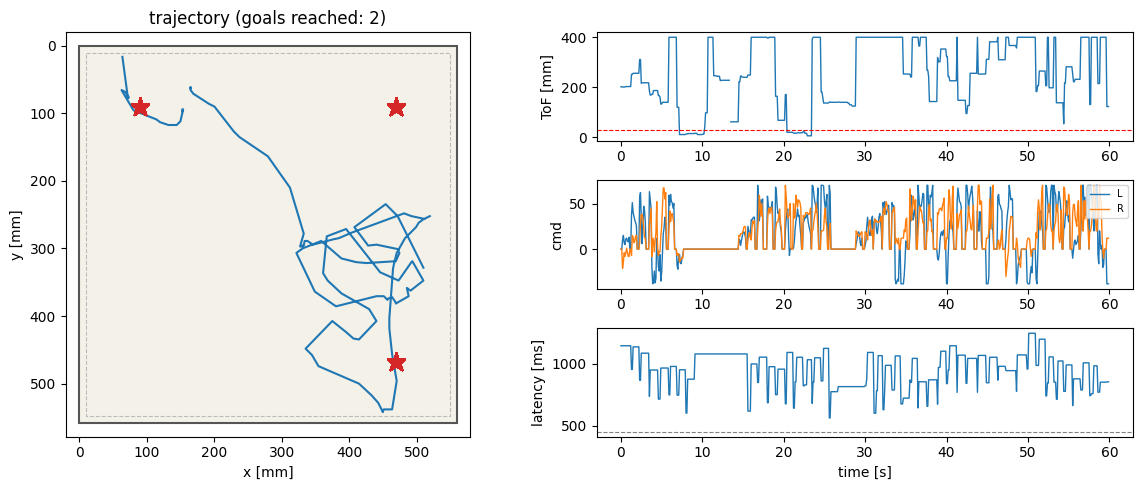

In [32]:
import time
d = log.to_dict()
log.save(f"{PROJECT_DIR}/runs/real_run_{time.strftime('%Y%m%d_%H%M%S')}.npz")
viz.plot_real_run(d, cfg, obstacles=vrobot.obstacles if vrobot else None);

## 5. 後片付け

In [33]:
bridge.stop_motors()
bridge.set_armed(False)  # DISARM (ARM は本体ボタンのみ)
bridge.close()
if vrobot:
    print(f"仮想ロボットの衝突回数: {vrobot.collisions}")
    vrobot.stop()

## うまくいかないとき

| 症状 | 対処 |
|---|---|
| `ロボットから状態が届きません` | `TOPIC_PREFIX` とブローカーが `config.h` と一致しているか。AtomS3 のシリアルログで `[MQTT] 接続` が出ているか |
| MQTT に接続できない | `transport="websockets"` とブローカーの WebSocket ポートを試す |
| 遅延が DR 範囲を超える | 地理的に近いブローカーを使う。`runs/suggested_config.json` で追加学習する |
| ToF が何もないのに 100〜300mm | 床を見ている。`suggested_config.json` (`tof_max_range_mm` を下げた設定) で再学習 |
| `heading_error_deg` が大きい / `turn_gain` が負 | 座標系の想定と実機が違う。toio の向き・マットの種類を確認 |
| よく障害物にぶつかる | 障害物が低い・黒い・細いと ToF で見えない。背が高く白っぽい箱で試す |